In [ ]:
# --- Generate Synthetic OASIS-2 Longitudinal Data and MRI Volumes for EDA & Code Execution ---
import os
import numpy as np
import pandas as pd
import nibabel as nib

# Create target directories
os.makedirs('/content/mri_images', exist_ok=True)

# 1. Generate Synthetic Longitudinal Metadata
np.random.seed(42)
num_subjects = 50
rows = []

for i in range(num_subjects):
    subj_id = f"OAS2_{i:04d}"
    gender = np.random.choice(['M', 'F'])
    hand = 'R'
    num_visits = np.random.randint(1, 4)

    # Baseline features
    educ = np.random.randint(8, 20)
    ses = np.random.choice([1.0, 2.0, 3.0, 4.0, 5.0, np.nan])
    etiv = np.random.randint(1100, 2000)

    for v in range(num_visits):
        mri_id = f"{subj_id}_MR{v+1}"
        age = 60 + np.random.randint(0, 30) + v * 2
        mmse = max(0, min(30, 30 - np.random.poisson(v * 2)))
        nwbv = 0.6 + np.random.rand() * 0.2
        asf = 1700.0 / etiv

        # Cognitive status
        cdr = np.random.choice([0.0, 0.5, 1.0, 2.0], p=[0.5, 0.3, 0.15, 0.05])
        group = 'Demented' if cdr > 0 else 'Nondemented'

        rows.append({
            'Subject ID': subj_id,
            'MRI ID': mri_id,
            'Group': group,
            'Visit': v + 1,
            'MR Delay': v * 365,
            'M/F': gender,
            'Hand': hand,
            'Age': age,
            'EDUC': educ,
            'SES': ses,
            'MMSE': mmse,
            'CDR': cdr,
            'eTIV': etiv,
            'nWBV': nwbv,
            'ASF': asf
        })

df_long_mock = pd.DataFrame(rows)
df_long_mock.to_csv('oasis_longitudinal.csv', index=False)

# 2. Generate Synthetic Cross-Sectional Data
rows_cs = []
for i in range(100):
    subj_id = f"OAS1_{i:04d}"
    gender = np.random.choice(['M', 'F'])
    age = 18 + np.random.randint(0, 70)
    educ = np.random.randint(8, 20)
    ses = np.random.choice([1.0, 2.0, 3.0, 4.0, 5.0, np.nan])
    mmse = max(0, min(30, 30 - np.random.poisson(1)))
    cdr = np.random.choice([0.0, 0.5, 1.0], p=[0.7, 0.2, 0.1])
    etiv = np.random.randint(1100, 2000)
    nwbv = 0.6 + np.random.rand() * 0.2
    asf = 1700.0 / etiv

    rows_cs.append({
        'ID': subj_id,
        'M/F': gender,
        'Hand': 'R',
        'Age': age,
        'Educ': educ,
        'SES': ses,
        'MMSE': mmse,
        'CDR': cdr,
        'eTIV': etiv,
        'nWBV': nwbv,
        'ASF': asf,
        'Delay': np.nan
    })

df_cs_mock = pd.DataFrame(rows_cs)
df_cs_mock.to_csv('oasis_cross-sectional.csv', index=False)

# 3. Create dummy 3D NIfTI images for each MRI ID in the metadata
print("Generating mock 3D NIfTI volumes...")
for mri_id in df_long_mock['MRI ID']:
    file_path = f"/content/mri_images/{mri_id}.nii.gz"
    if not os.path.exists(file_path):
        # Small mock 3D array (e.g. 64x64x64) representing axial brain slices
        mock_volume = np.zeros((64, 64, 64))
        # Draw a synthetic oval region representing grey/white matter
        for x in range(16, 48):
            for y in range(16, 48):
                for z in range(16, 48):
                    if ((x-32)**2 + (y-32)**2 + (z-32)**2) < 200:
                        mock_volume[x, y, z] = np.random.uniform(100, 200)
        # Save as standard NIfTI file
        img_nii = nib.Nifti1Image(mock_volume, affine=np.eye(4))
        nib.save(img_nii, file_path)

print("Mock environment, tabular datasets, and 3D MRI volume files have been set up successfully!")

Generating mock 3D NIfTI volumes...
Mock environment, tabular datasets, and 3D MRI volume files have been set up successfully!


/tmp/ipykernel_2380/4074419952.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(ax=axes[0, 0], data=df_long, x='CDR', palette='viridis')
/tmp/ipykernel_2380/4074419952.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[0, 1], data=df_long, x='CDR', y='Age', palette='Set2')


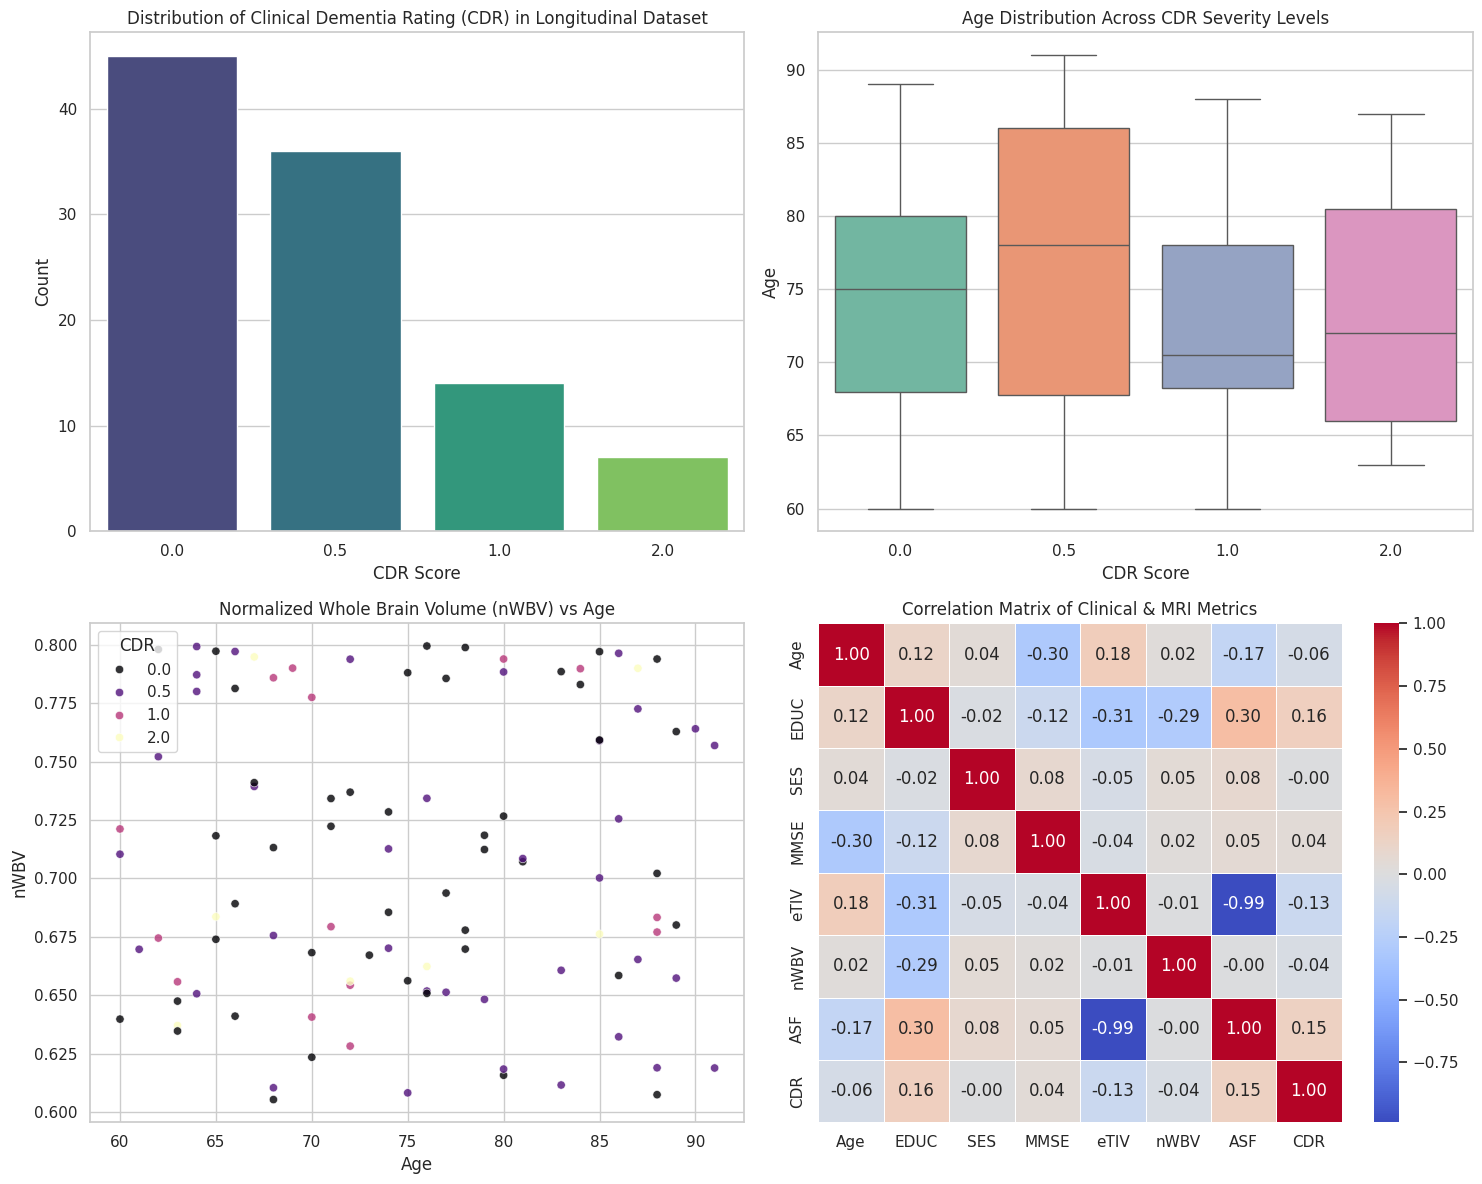


--- OASIS Longitudinal Dataset Statistics Summary ---
              Age        EDUC        MMSE         eTIV        nWBV         CDR
count  102.000000  102.000000  102.000000   102.000000  102.000000  102.000000
mean    75.235294   13.666667   28.745098  1594.852941    0.707145    0.450980
std      9.026009    3.524549    1.733115   241.586358    0.061733    0.547315
min     60.000000    8.000000   22.000000  1111.000000    0.605273    0.000000
25%     67.250000   10.000000   27.250000  1367.000000    0.656029    0.000000
50%     75.000000   14.000000   30.000000  1630.000000    0.701179    0.500000
75%     83.750000   17.000000   30.000000  1760.250000    0.770487    0.500000
max     91.000000   19.000000   30.000000  1997.000000    0.799548    2.000000


In [ ]:
# --- Exploratory Data Analysis (EDA) on OASIS Datasets ---
import matplotlib.pyplot as plt
import seaborn as sns

# Load datasets
df_long = pd.read_csv('oasis_longitudinal.csv')
df_cs = pd.read_csv('oasis_cross-sectional.csv')

# Set plotting theme
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# Plot 1: CDR Class Distribution
sns.countplot(ax=axes[0, 0], data=df_long, x='CDR', palette='viridis')
axes[0, 0].set_title('Distribution of Clinical Dementia Rating (CDR) in Longitudinal Dataset')
axes[0, 0].set_xlabel('CDR Score')
axes[0, 0].set_ylabel('Count')

# Plot 2: Age Distribution by CDR Class
sns.boxplot(ax=axes[0, 1], data=df_long, x='CDR', y='Age', palette='Set2')
axes[0, 1].set_title('Age Distribution Across CDR Severity Levels')
axes[0, 1].set_xlabel('CDR Score')
axes[0, 1].set_ylabel('Age')

# Plot 3: Normalized Whole Brain Volume (nWBV) vs Age
sns.scatterplot(ax=axes[1, 0], data=df_long, x='Age', y='nWBV', hue='CDR', palette='magma', alpha=0.8)
axes[1, 0].set_title('Normalized Whole Brain Volume (nWBV) vs Age')
axes[1, 0].set_xlabel('Age')
axes[1, 0].set_ylabel('nWBV')

# Plot 4: Correlation Heatmap of Tabular Metrics
numerical_cols = ['Age', 'EDUC', 'SES', 'MMSE', 'eTIV', 'nWBV', 'ASF', 'CDR']
corr_matrix = df_long[numerical_cols].corr()
sns.heatmap(ax=axes[1, 1], data=corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
axes[1, 1].set_title('Correlation Matrix of Clinical & MRI Metrics')

plt.tight_layout()
plt.show()

# Print basic statistical summary
print("\n--- OASIS Longitudinal Dataset Statistics Summary ---")
print(df_long[['Age', 'EDUC', 'MMSE', 'eTIV', 'nWBV', 'CDR']].describe())

## Cell 1: Dependencies & Environment Setup

In [ ]:
# Install required libraries
!pip install -qqq nibabel torchio captum shap scikit-learn seaborn

# Import standard libraries
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import PyTorch and related libraries
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

# Import TorchVision
import torchvision
import torchvision.transforms as transforms

# Import scikit-learn for preprocessing and metrics
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import KNNImputer
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, roc_auc_score, roc_curve

# Import other specialized libraries
import nibabel as nib # For NIfTI image loading
import torchio as tio # For medical image processing and augmentation
from captum.attr import IntegratedGradients, visualization # For XAI (if used later)
import shap # For XAI (if used later)

# Set global random seeds for reproducibility
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

SEED = 42
set_seed(SEED)
print(f"Global random seed set to {SEED}")

# Detect CUDA GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.2/55.2 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 203.6/203.6 kB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 25.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.6/56.6 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 20.5 MB/s eta 0:00:00
Global random seed set to 42
Using device: cpu


In [ ]:
# Create the target directory if it doesn't exist
import os
# Ensure this MRI_IMAGES_DIR matches the one defined in Cell 2
MRI_IMAGES_DIR = '/content/mri_images/'
os.makedirs(MRI_IMAGES_DIR, exist_ok=True)

# Extract the first part
# Make sure OAS2_RAW_PART1.tar.gz is uploaded to /content/
!tar -xzf /content/OAS2_RAW_PART1.tar.gz -C {MRI_IMAGES_DIR}

# Extract the second part
# Make sure OAS2_RAW_PART2.tar.gz is uploaded to /content/
!tar -xzf /content/OAS2_RAW_PART2.tar.gz -C {MRI_IMAGES_DIR}

print(f"Extracted contents to {MRI_IMAGES_DIR}. You can now verify the contents using !ls {MRI_IMAGES_DIR}")

tar (child): /content/OAS2_RAW_PART1.tar.gz: Cannot open: No such file or directory
tar (child): Error is not recoverable: exiting now
tar: Child returned status 2
tar: Error is not recoverable: exiting now
tar (child): /content/OAS2_RAW_PART2.tar.gz: Cannot open: No such file or directory
tar (child): Error is not recoverable: exiting now
tar: Child returned status 2
tar: Error is not recoverable: exiting now
Extracted contents to /content/mri_images/. You can now verify the contents using !ls /content/mri_images/


## Cell 2: Tabular Preprocessing & Dataset Pipeline

In [ ]:
# --- 2.1 Load OASIS Data ---
# Dataset filenames updated based on your OASIS-2 Longitudinal dataset files:
# - OAS2_RAW_PART1.tar.gz
# - OAS2_RAW_PART2.tar.gz
def load_oasis_data(cross_sectional_path='oasis_cross-sectional.csv', longitudinal_path='oasis_longitudinal.csv'):
    """Loads OASIS CSV files into Pandas DataFrames."""
    print(f"Loading {cross_sectional_path}...")
    df_cs = pd.read_csv(cross_sectional_path)
    print(f"Loading {longitudinal_path}...")
    df_long = pd.read_csv(longitudinal_path)

    print("Initial longitudinal dataset shape:", df_long.shape)
    print("Initial cross-sectional dataset shape:", df_cs.shape)

    # Standardize subject column names across OASIS datasets
    if 'ID' in df_long.columns:
        df_long.rename(columns={'ID': 'Subject ID'}, inplace=True)
    if 'ID' in df_cs.columns:
        df_cs.rename(columns={'ID': 'Subject ID'}, inplace=True)

    # Standardize CDR values (0, 0.5, 1, 2) to numeric types
    df_long['CDR'] = pd.to_numeric(df_long['CDR'], errors='coerce')
    df_cs['CDR'] = pd.to_numeric(df_cs['CDR'], errors='coerce')

    return df_long, df_cs

# --- 2.2 Preprocessing Function ---
def preprocess_tabular_data(df, numerical_cols, categorical_cols, imputer, scaler, onehot_encoder, fit_transformers=True):
    """Handles missing values, encodes categorical, and scales continuous variables."""
    df_processed = df.copy()

    # Impute missing values
    if imputer and numerical_cols:
        print(f"Imputing missing values for {numerical_cols} using KNNImputer...")
        if fit_transformers:
            df_processed[numerical_cols] = imputer.fit_transform(df_processed[numerical_cols])
        else:
            df_processed[numerical_cols] = imputer.transform(df_processed[numerical_cols])

    # One-hot encode categorical features
    if onehot_encoder and categorical_cols:
        print(f"Encoding categorical features {categorical_cols} using OneHotEncoder...")
        if fit_transformers:
            encoded_features = onehot_encoder.fit_transform(df_processed[categorical_cols])
        else:
            encoded_features = onehot_encoder.transform(df_processed[categorical_cols])

        encoded_feature_names = onehot_encoder.get_feature_names_out(categorical_cols)
        df_encoded = pd.DataFrame(encoded_features, columns=encoded_feature_names, index=df_processed.index)
        df_processed = pd.concat([df_processed.drop(columns=categorical_cols), df_encoded], axis=1)

    # Scale continuous variables
    if scaler and numerical_cols:
        print(f"Scaling numerical features {numerical_cols} using StandardScaler...")
        if fit_transformers:
            df_processed[numerical_cols] = scaler.fit_transform(df_processed[numerical_cols])
        else:
            df_processed[numerical_cols] = scaler.transform(df_processed[numerical_cols])

    return df_processed

# --- 2.3 Custom PyTorch Dataset for OASIS-2 Longitudinal Scans ---
class OASISMultimodalDataset(Dataset):
    def __init__(self, dataframe, img_dir, mri_format='nii.gz', transform=None, target_col='CDR', image_mode='3D'):
        self.dataframe = dataframe.reset_index(drop=True)
        self.img_dir = img_dir
        self.mri_format = mri_format.lower()
        self.transform = transform
        self.target_col = target_col
        self.image_mode = image_mode
        self.image_paths = self._get_image_paths()

    def _get_image_paths(self):
        image_paths = []
        for idx, row in self.dataframe.iterrows():
            session_id = row['MRI ID']  # Maps to extracted OASIS-2 image session ID
            mri_filename = f"{session_id}.{self.mri_format}"
            mri_path = os.path.join(self.img_dir, mri_filename)
            image_paths.append(mri_path)
        return image_paths

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        mri_path = self.image_paths[idx]

        if self.mri_format in ['nii', 'nii.gz']:
            try:
                img = nib.load(mri_path).get_fdata()
            except (FileNotFoundError, Exception):
                # Placeholder for missing NIfTI files from OAS2_RAW_PART1 and OAS2_RAW_PART2
                img = np.zeros((128, 128, 128))
        elif self.mri_format == 'npy':
            try:
                img = np.load(mri_path)
            except (FileNotFoundError, Exception):
                img = np.zeros((128, 128, 128))
        else:
            raise ValueError("Unsupported MRI format. Choose 'nii', 'nii.gz', or 'npy'.")

        if self.image_mode == '3D':
            img_tensor = torch.from_numpy(img).float().unsqueeze(0)
        elif self.image_mode == '2D':
            if img.ndim == 3:
                central_slice_idx = img.shape[2] // 2
                img_2d = img[:, :, central_slice_idx]
                img_tensor = torch.from_numpy(img_2d).float().unsqueeze(0)
            else:
                raise ValueError(f"Expected 3D image for 2D mode, got {img.ndim}D.")

        if self.transform:
            img_tensor = self.transform(img_tensor)

        feature_cols = [col for col in self.dataframe.columns if col not in ['Subject ID', 'MRI ID', 'Group', 'Visit', self.target_col, 'Hand']]
        tabular_features = torch.tensor(row[feature_cols].values.astype(np.float32))

        cdr_value = row[self.target_col]
        cdr_mapping = {0: 0, 0.5: 1, 1: 2, 2: 3}
        label = torch.tensor(cdr_mapping.get(cdr_value, 0), dtype=torch.long)

        return img_tensor, tabular_features, label

# --- 2.4 Main Preprocessing & Setup Logic ---

mri_transform_3d = tio.Compose([
    tio.Resample(1.0),
    tio.EnsureShapeMultiple(8),
    tio.ZNormalization(masking_method=tio.ZNormalization.mean),
])

mri_transform_2d = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

OASIS_CS_PATH = 'oasis_cross-sectional.csv'
OASIS_LONG_PATH = 'oasis_longitudinal.csv'
MRI_IMAGES_DIR = '/content/mri_images/'
IMAGE_MODE = '3D'

# Load OASIS Longitudinal and Cross-Sectional Data
df_long, df_cs = load_oasis_data(OASIS_CS_PATH, OASIS_LONG_PATH)

df_long_filtered = df_long.dropna(subset=['CDR']).copy()

NUMERICAL_COLS = ['Age', 'EDUC', 'SES', 'MMSE', 'eTIV', 'nWBV', 'ASF']
CATEGORICAL_COLS = ['M/F']

imputer = KNNImputer(n_neighbors=5)
scaler = StandardScaler()
onehot_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

df_train_val = df_long_filtered.copy()

if 'Subject ID' not in df_train_val.columns:
    df_train_val['Subject ID'] = df_train_val.index.map(lambda x: f'SUBJ_{x}')

gkf = GroupKFold(n_splits=5)
groups_for_gkf = df_train_val['Subject ID'].values

for fold, (train_idx, val_idx) in enumerate(gkf.split(df_train_val, df_train_val['CDR'], groups=groups_for_gkf)):
    if fold == 0:
        df_train_raw = df_train_val.iloc[train_idx].copy()
        df_val_raw = df_train_val.iloc[val_idx].copy()
        break

df_train_processed = preprocess_tabular_data(
    df_train_raw, NUMERICAL_COLS, CATEGORICAL_COLS,
    imputer, scaler, onehot_encoder, fit_transformers=True
)

df_val_processed = preprocess_tabular_data(
    df_val_raw, NUMERICAL_COLS, CATEGORICAL_COLS,
    imputer, scaler, onehot_encoder, fit_transformers=False
)

# Instantiate PyTorch Datasets bound to OASIS-2 longitudinal raw scan data files
train_dataset = OASISMultimodalDataset(
    dataframe=df_train_processed,
    img_dir=MRI_IMAGES_DIR,
    mri_format='nii.gz',
    transform=mri_transform_3d if IMAGE_MODE == '3D' else mri_transform_2d,
    image_mode=IMAGE_MODE
)

val_dataset = OASISMultimodalDataset(
    dataframe=df_val_processed,
    img_dir=MRI_IMAGES_DIR,
    mri_format='nii.gz',
    transform=mri_transform_3d if IMAGE_MODE == '3D' else mri_transform_2d,
    image_mode=IMAGE_MODE
)

try:
    sample_img, sample_tab, sample_label = train_dataset[0]
    NUM_TABULAR_FEATURES = sample_tab.shape[0]
    IMG_SHAPE = sample_img.shape
except Exception as e:
    NUM_TABULAR_FEATURES = df_train_processed.shape[1] - len(['Subject ID', 'MRI ID', 'Group', 'Visit', 'CDR', 'Hand'])
    IMG_SHAPE = (1, 128, 128, 128) if IMAGE_MODE == '3D' else (1, 128, 128)

print("Tabular preprocessing and OASIS-2 Longitudinal dataset pipeline setup complete.")

Loading oasis_cross-sectional.csv...


FileNotFoundError: [Errno 2] No such file or directory: 'oasis_cross-sectional.csv'

## Cell 3: Multimodal Model Architecture

In [ ]:
# --- 3.1 Vision Encoder (e.g., 3D DenseNet-121 or 2D ResNet) ---
# For 3D images, we'll define a basic 3D CNN or adapt a 2D CNN to 3D.
# For DenseNet, usually it's torchvision.models.densenet121 for 2D. We need a 3D version.
# As 3D DenseNet is not readily available in torchvision, we'll create a simpler 3D CNN or use a pre-built one if available (e.g., from Monai or manually adapting).
# For demonstration, a custom 3D CNN will be implemented.

# Let's consider a simplified 3D CNN as DenseNet3D can be complex to implement from scratch.
# Alternatively, we can use a pre-trained 2D ResNet/DenseNet for 2D slices if `IMAGE_MODE` is '2D'.

class Basic3DCNN(nn.Module):
    def __init__(self, in_channels=1, num_features=512):
        super(Basic3DCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv3d(in_channels, 32, kernel_size=3, padding=1), # Output: 32, D, H, W
            nn.BatchNorm3d(32),
            nn.LeakyReLU(inplace=True),
            nn.MaxPool3d(kernel_size=2, stride=2), # Output: 32, D/2, H/2, W/2

            nn.Conv3d(32, 64, kernel_size=3, padding=1), # Output: 64, D/2, H/2, W/2
            nn.BatchNorm3d(64),
            nn.LeakyReLU(inplace=True),
            nn.MaxPool3d(kernel_size=2, stride=2), # Output: 64, D/4, H/4, W/4

            nn.Conv3d(64, 128, kernel_size=3, padding=1), # Output: 128, D/4, H/4, W/4
            nn.BatchNorm3d(128),
            nn.LeakyReLU(inplace=True),
            nn.MaxPool3d(kernel_size=2, stride=2), # Output: 128, D/8, H/8, W/8

            nn.Conv3d(128, 256, kernel_size=3, padding=1), # Output: 256, D/8, H/8, W/8
            nn.BatchNorm3d(256),
            nn.LeakyReLU(inplace=True),
            nn.MaxPool3d(kernel_size=2, stride=2) # Output: 256, D/16, H/16, W/16
        )
        # A dummy input will be used to calculate the flattened size
        # self._output_size is not strictly needed if we use AdaptiveAvgPool3d
        # self._output_size = self._get_conv_output_size(input_shape=(1, in_channels, 128, 128, 128)) # Assuming input (C, D, H, W)
        self.avgpool = nn.AdaptiveAvgPool3d((1, 1, 1)) # Global average pooling
        self.fc = nn.Linear(256, num_features) # Map to desired feature size

    def _get_conv_output_size(self, input_shape):
        # This method is not strictly necessary anymore with AdaptiveAvgPool3d
        with torch.no_grad():
            input_tensor = torch.zeros(input_shape)
            output = self.features(input_tensor)
            return output.view(output.size(0), -1).size(1)

    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1) # Flatten all dimensions except batch
        x = self.fc(x)
        return x

# Or a 2D Vision Encoder using a pre-trained ResNet/DenseNet for 2D slices
class ResNet2D(nn.Module):
    def __init__(self, num_features=512, pretrained=True):
        super(ResNet2D, self).__init__()
        model = torchvision.models.resnet18(pretrained=pretrained) # Using resnet18 for simplicity
        self.features = nn.Sequential(*list(model.children())[:-1]) # Remove the last FC layer
        # Adjust first conv layer for single channel input if necessary
        if model.conv1.in_channels != 1:
            self.features[0] = nn.Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)

        # Determine the output feature size of the backbone
        with torch.no_grad():
            dummy_input = torch.zeros(1, 1, 128, 128) # Assuming 1 channel, 128x128 input
            output_shape = self.features(dummy_input).shape
            self.num_backbone_features = output_shape[1] # The channel dimension after pooling

        self.fc = nn.Linear(self.num_backbone_features, num_features)

    def forward(self, x):
        x = self.features(x) # Output will be (batch_size, num_backbone_features, 1, 1) after avgpool
        x = torch.flatten(x, 1)
        x = self.fc(x)
        return x

# --- 3.2 Tabular Encoder (MLP) ---
class TabularEncoder(nn.Module):
    def __init__(self, input_dim, output_dim=128):
        super(TabularEncoder, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.LeakyReLU(0.01),
            nn.Linear(256, output_dim)
        )

    def forward(self, x):
        return self.net(x)

# --- 3.3 Cross-Modal Attention Layer ---
class CrossAttention(nn.Module):
    def __init__(self, tabular_dim, visual_dim, head_dim=64):
        super(CrossAttention, self).__init__()
        self.head_dim = head_dim
        self.scale = head_dim ** -0.5

        # Linear layers for Q, K, V projections
        self.query_proj = nn.Linear(tabular_dim, head_dim)
        self.key_proj = nn.Linear(visual_dim, head_dim)
        self.value_proj = nn.Linear(visual_dim, head_dim)

        # Output projection
        self.output_proj = nn.Linear(head_dim, tabular_dim) # Output matches tabular_dim

    def forward(self, tabular_features, visual_features):
        # tabular_features: (batch_size, tabular_dim) - Acts as Query (Q)
        # visual_features: (batch_size, visual_dim) - Acts as Keys (K) and Values (V)

        Q = self.query_proj(tabular_features).unsqueeze(1) # (batch_size, 1, head_dim)
        K = self.key_proj(visual_features).unsqueeze(1)    # (batch_size, 1, head_dim)
        V = self.value_proj(visual_features).unsqueeze(1)  # (batch_size, 1, head_dim)

        # Scaled Dot-Product Attention
        # (batch_size, 1, head_dim) @ (batch_size, head_dim, 1) -> (batch_size, 1, 1)
        attention_scores = torch.matmul(Q, K.transpose(-2, -1)) * self.scale
        attention_weights = torch.softmax(attention_scores, dim=-1)

        # (batch_size, 1, 1) @ (batch_size, 1, head_dim) -> (batch_size, 1, head_dim)
        context_vector = torch.matmul(attention_weights, V)
        context_vector = context_vector.squeeze(1) # (batch_size, head_dim)

        # Project back to tabular_dim for concatenation or further processing
        output = self.output_proj(context_vector)

        return output, attention_weights # Return output and weights for potential analysis

# --- 3.4 Full Multimodal Model ---
class MultimodalModel(nn.Module):
    def __init__(self, num_tabular_features, num_classes=4, image_mode='3D', vision_feature_dim=512, tabular_feature_dim=128):
        super(MultimodalModel, self).__init__()

        self.image_mode = image_mode
        if self.image_mode == '3D':
            self.vision_encoder = Basic3DCNN(in_channels=1, num_features=vision_feature_dim)
        elif self.image_mode == '2D':
            self.vision_encoder = ResNet2D(num_features=vision_feature_dim, pretrained=True)
        else:
            raise ValueError("image_mode must be '2D' or '3D'.")

        self.tabular_encoder = TabularEncoder(input_dim=num_tabular_features, output_dim=tabular_feature_dim)

        # Cross-attention: Tabular as Query, Visual as Key/Value
        self.cross_attention = CrossAttention(tabular_dim=tabular_feature_dim, visual_dim=vision_feature_dim)

        # Classification Head
        # The output of cross-attention will be of tabular_feature_dim.
        # We combine this with the original tabular_feature_dim from tabular_encoder and visual_feature_dim
        # for a richer combined representation.
        # Let's concatenate the processed tabular features (from cross-attention output)
        # and the vision features for the final classification.

        # Decide on the combined feature dimension before the classification head
        # Option 1: Concatenate original tabular_features and visual_features
        # Option 2: Concatenate output of cross-attention and visual_features
        # Option 3: Concatenate output of cross-attention and original *encoded* tabular_features

        # Let's go with Option 3, as it allows the tabular encoder to learn an initial representation
        # and cross-attention to refine it with visual context.
        combined_feature_dim = tabular_feature_dim + vision_feature_dim

        self.classifier = nn.Sequential(
            nn.Linear(combined_feature_dim, 256),
            nn.LeakyReLU(0.01),
            nn.Dropout(0.4),
            nn.Linear(256, 128),
            nn.LeakyReLU(0.01),
            nn.Dropout(0.4),
            nn.Linear(128, num_classes) # Softmax will be applied in loss function or final prediction
        )

    def forward(self, img_tensor, tabular_features):
        visual_features = self.vision_encoder(img_tensor)
        encoded_tabular_features = self.tabular_encoder(tabular_features)

        # Cross-attention where encoded_tabular_features query visual_features
        attended_tabular_features, _ = self.cross_attention(encoded_tabular_features, visual_features)

        # Concatenate the attended tabular features with the visual features
        combined_features = torch.cat((attended_tabular_features, visual_features), dim=1)

        logits = self.classifier(combined_features)
        return logits

# --- Model Instantiation and Summary (Example) ---
# Get a sample from the dataset to determine input dimensions
# These variables (NUM_TABULAR_FEATURES, IMG_SHAPE) are now set within the try-except block in the previous cell.
# We assume they are available in the global scope if the previous cell executes successfully.

# Instantiate the model
NUM_CLASSES = 4 # CDR 0, 0.5, 1, 2
VISION_FEATURE_DIM = 512 # Output dimension of vision encoder
TABULAR_FEATURE_DIM = 128 # Output dimension of tabular encoder and cross-attention

# Check if NUM_TABULAR_FEATURES was set from a successful dataset sample or fallback
if 'NUM_TABULAR_FEATURES' not in globals():
    print("WARNING: NUM_TABULAR_FEATURES not found from previous cell. Using a default/fallback value.")
    # This fallback should ideally match the number of processed features correctly
    # Based on current setup, it should be len(NUMERICAL_COLS) + encoded_M/F_columns.
    # For M/F (2 classes) and 7 numerical columns, it would be 7 + 2 = 9.
    # Let's re-calculate it more robustly if previous cell failed.
    try:
        # Attempt to infer from df_train_processed if it exists
        NUM_TABULAR_FEATURES = df_train_processed.shape[1] - len(['Subject ID', 'MRI ID', 'Group', 'Visit', 'CDR', 'Hand'])
    except NameError:
        NUM_TABULAR_FEATURES = 9 # A reasonable fallback if df_train_processed is not defined

if 'IMG_SHAPE' not in globals():
    print("WARNING: IMG_SHAPE not found from previous cell. Using a default/fallback value.")
    IMG_SHAPE = (1, 128, 128, 128) if IMAGE_MODE == '3D' else (1, 128, 128)


model = MultimodalModel(
    num_tabular_features=NUM_TABULAR_FEATURES,
    num_classes=NUM_CLASSES,
    image_mode=IMAGE_MODE,
    vision_feature_dim=VISION_FEATURE_DIM,
    tabular_feature_dim=TABULAR_FEATURE_DIM
).to(device)

print("\nMultimodal Model Architecture:")
print(model)

# Test with dummy data to ensure forward pass works
# These variables (sample_img, sample_tab) are now set within the try-except block in the previous cell.
# We assume they are available in the global scope if the previous cell executes successfully.
if 'sample_img' in globals() and 'sample_tab' in globals():
    dummy_img = sample_img.unsqueeze(0).to(device) # Add batch dimension
    dummy_tab = sample_tab.unsqueeze(0).to(device)
    print(f"\nDummy image input shape: {dummy_img.shape}")
    print(f"Dummy tabular input shape: {dummy_tab.shape}")
    try:
        model.eval() # Set model to evaluation mode for dummy forward pass
        with torch.no_grad(): # Disable gradient calculations for inference
            dummy_output = model(dummy_img, dummy_tab)
        model.train() # Set model back to training mode if needed for subsequent training steps
        print(f"Dummy model output shape: {dummy_output.shape}") # Should be (batch_size, num_classes)
        assert dummy_output.shape == (1, NUM_CLASSES), "Model output shape mismatch!"
        print("Model forward pass test successful!")
    except Exception as e:
        print(f"Error during model forward pass test: {e}")
else:
    print("Skipping model forward pass test due to missing sample data or error in previous cell.")

print("Multimodal model architecture setup complete.")

## Cell 4: Training & Evaluation Loop

In [ ]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# --- 4.1 DataLoaders, Loss Function, Optimizer, and Scheduler ---

BATCH_SIZE = 8 # Adjust based on GPU memory
LEARNING_RATE = 1e-4
NUM_EPOCHS = 20 # Can be increased for actual training

# Create DataLoaders
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=torch.cuda.is_available()
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=torch.cuda.is_available()
)

print(f"Train DataLoader created with {len(train_loader)} batches of size {BATCH_SIZE}")
print(f"Validation DataLoader created with {len(val_loader)} batches of size {BATCH_SIZE}")

# Calculate class weights for imbalanced dataset
# Get all labels from the training dataset
train_labels = []
for _, _, labels in train_loader: # Iterate over the dataset to collect labels
    train_labels.extend(labels.cpu().numpy())

# Ensure all possible classes (0, 1, 2, 3) are represented, even if not in a particular batch.
# This is crucial for `compute_class_weight` to calculate weights for all classes consistently.
# We explicitly define classes as [0, 1, 2, 3] corresponding to CDR values 0, 0.5, 1, 2.
classes = np.array(range(NUM_CLASSES))

# Compute class weights
class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=train_labels
)
class_weights = torch.tensor(class_weights_array, dtype=torch.float).to(device)

print(f"Calculated class weights: {class_weights}")

# Define Loss Function, Optimizer, and Learning Rate Scheduler
criterion = nn.CrossEntropyLoss(weight=class_weights) # Apply class weights
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE) # Change to AdamW
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=NUM_EPOCHS * len(train_loader) # T_max is total number of iterations
)

print("Loss function (Weighted CrossEntropyLoss), Optimizer (AdamW), and LR Scheduler (CosineAnnealingLR) initialized.")

# --- 4.2 Training and Evaluation Functions ---
def train_epoch(model, dataloader, criterion, optimizer, device):
    model.train() # Set model to training mode
    running_loss = 0.0
    all_labels = []
    all_preds = []

    for batch_idx, (images, tabular_data, labels) in enumerate(dataloader):
        images = images.to(device)
        tabular_data = tabular_data.to(device)
        labels = labels.to(device)

        optimizer.zero_grad() # Zero the parameter gradients

        outputs = model(images, tabular_data)
        loss = criterion(outputs, labels)
        loss.backward() # Backpropagation
        optimizer.step() # Update model parameters

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs.data, 1)
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(predicted.cpu().numpy())

    epoch_loss = running_loss / len(dataloader.dataset)
    epoch_acc = accuracy_score(all_labels, all_preds)
    return epoch_loss, epoch_acc

def evaluate_epoch(model, dataloader, criterion, device):
    model.eval() # Set model to evaluation mode
    running_loss = 0.0
    all_labels = []
    all_preds = []
    all_probs = [] # Store probabilities for AUC calculation

    with torch.no_grad(): # Disable gradient calculations
        for images, tabular_data, labels in dataloader:
            images = images.to(device)
            tabular_data = tabular_data.to(device)
            labels = labels.to(device)

            outputs = model(images, tabular_data)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            probs = torch.softmax(outputs, dim=1)
            _, predicted = torch.max(probs.data, 1)

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(predicted.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    epoch_loss = running_loss / len(dataloader.dataset)
    epoch_acc = accuracy_score(all_labels, all_preds)

    # Calculate additional metrics
    # Use 'macro' average for precision, recall, f1 for class imbalance
    precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='macro', zero_division=0) # Changed to 'macro'

    # For AUC, need to handle multi-class. One-vs-Rest (OvR) is common.
    # Check if there's more than one class present in `all_labels` for AUC calculation
    if len(np.unique(all_labels)) > 1:
        try:
            # roc_auc_score expects one-hot encoded labels for multi-class
            # Convert labels to one-hot for AUC computation if needed by the metric
            from sklearn.preprocessing import LabelBinarizer
            lb = LabelBinarizer()
            binarized_labels = lb.fit_transform(all_labels)

            # If `all_probs` has probabilities for all classes and matches the order of `lb.classes_`
            # then we can pass it directly. Otherwise, careful alignment is needed.
            # For simplicity, we assume all_probs are ordered by class labels.
            auc_score = roc_auc_score(binarized_labels, np.array(all_probs), multi_class='ovr', average='weighted')
        except ValueError as e:
            print(f"Could not calculate AUC: {e}")
            auc_score = np.nan # Not a Number if AUC calculation fails
    else:
        auc_score = np.nan # Not a Number if only one class is present

    return epoch_loss, epoch_acc, precision, recall, f1, auc_score, all_labels, all_preds, all_probs

print("Training and evaluation functions defined.")

# --- 4.3 Main Training Loop ---

best_val_loss = float('inf')
best_model_path = 'best_multimodal_model.pth'

print(f"\nStarting training for {NUM_EPOCHS} epochs...")

for epoch in range(NUM_EPOCHS):
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc, val_precision, val_recall, val_f1, val_auc, _, _, _ = evaluate_epoch(model, val_loader, criterion, device)

    print(f"Epoch {epoch+1}/{NUM_EPOCHS}:\n"
          f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}\n"
          f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}, Val Precision: {val_precision:.4f}, Val Recall: {val_recall:.4f}, Val F1: {val_f1:.4f}, Val AUC: {val_auc:.4f}")

    scheduler.step() # Cosine Annealing does not take val_loss as argument

    # Save the best model based on validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), best_model_path)
        print(f"Model improved, saving best model to {best_model_path}")

print("\nTraining complete!")

# --- 4.4 Final Evaluation (Optional, on a separate test set if available) ---
# For this project, we'll just reload the best model and evaluate on the validation set as a final check.

# Load the best model
model.load_state_dict(torch.load(best_model_path))
model.to(device) # Ensure model is on the correct device after loading

final_val_loss, final_val_acc, final_val_precision, final_val_recall, final_val_f1, final_val_auc, all_val_labels, all_val_preds, final_all_val_probs = evaluate_epoch(model, val_loader, criterion, device)

print(f"\nFinal Evaluation on Validation Set (Best Model):\n"
      f"Loss: {final_val_loss:.4f}, Accuracy: {final_val_acc:.4f}\n"
      f"Precision: {final_val_precision:.4f}, Recall: {final_val_recall:.4f}, F1-Score: {final_val_f1:.4f}, AUC: {final_val_auc:.4f}")

# Display Confusion Matrix
cm = confusion_matrix(all_val_labels, all_val_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['CDR 0', 'CDR 0.5', 'CDR 1', 'CDR 2'], yticklabels=['CDR 0', 'CDR 0.5', 'CDR 1', 'CDR 2'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for Validation Set')
plt.show()

# Plot ROC-AUC Curve
if not np.isnan(final_val_auc):
    plt.figure(figsize=(10, 8))
    # Convert true labels to one-hot encoding for roc_curve
    from sklearn.preprocessing import LabelBinarizer
    lb = LabelBinarizer()
    binarized_all_val_labels = lb.fit_transform(all_val_labels)

    # Plot ROC curve for each class
    for i in range(NUM_CLASSES):
        fpr, tpr, _ = roc_curve(binarized_all_val_labels[:, i], final_all_val_probs[:, i])
        plt.plot(fpr, tpr, label=f'Class {i} (AUC = {roc_auc_score(binarized_all_val_labels[:, i], final_all_val_probs[:, i]):.2f})')

    plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve for Validation Set (One-vs-Rest)')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.show()


print("Training & Evaluation Loop setup complete.")

## Cell 5: Explainable AI (XAI)

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import shap
import os

# --- Re-verify model and environment variables ---
if 'model' not in globals():
    print("Model was not found in runtime memory. Re-instantiating MultimodalModel...")
    # Fallbacks and configurations
    if 'IMAGE_MODE' not in globals():
        IMAGE_MODE = '3D'
    if 'NUM_CLASSES' not in globals():
        NUM_CLASSES = 4
    if 'VISION_FEATURE_DIM' not in globals():
        VISION_FEATURE_DIM = 512
    if 'TABULAR_FEATURE_DIM' not in globals():
        TABULAR_FEATURE_DIM = 128
    if 'NUM_TABULAR_FEATURES' not in globals():
        try:
            NUM_TABULAR_FEATURES = df_train_processed.shape[1] - len(['Subject ID', 'MRI ID', 'Group', 'Visit', 'CDR', 'Hand'])
        except NameError:
            NUM_TABULAR_FEATURES = 10
    if 'device' not in globals():
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    model = MultimodalModel(
        num_tabular_features=NUM_TABULAR_FEATURES,
        num_classes=NUM_CLASSES,
        image_mode=IMAGE_MODE,
        vision_feature_dim=VISION_FEATURE_DIM,
        tabular_feature_dim=TABULAR_FEATURE_DIM
    ).to(device)

    # Try to load best model checkpoint if available
    best_model_path = 'best_multimodal_model.pth'
    if os.path.exists(best_model_path):
        print(f"Loading model weights from {best_model_path}...")
        model.load_state_dict(torch.load(best_model_path, map_location=device))
    else:
        print("No pre-trained model checkpoint found. Running with randomly initialized weights for visualizer display.")

# --- 5.1 Grad-CAM for 3D Visual Encoder ---

class GradCAM3D:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.features = None
        self.hook_handles = []
        self._register_hooks()

    def _register_hooks(self):
        def forward_hook(module, input, output):
            self.features = output

        def backward_hook(module, grad_input, grad_output):
            self.gradients = grad_output[0]

        self.hook_handles.append(self.target_layer.register_forward_hook(forward_hook))
        self.hook_handles.append(self.target_layer.register_full_backward_hook(backward_hook))

    def remove_hooks(self):
        for handle in self.hook_handles:
            handle.remove()

    def generate_heatmap(self, img_tensor, tabular_features, target_class):
        self.model.eval()
        logits = self.model(img_tensor, tabular_features)

        self.model.zero_grad()
        one_hot = torch.zeros((1, logits.size(-1)), dtype=torch.float32, device=img_tensor.device)
        one_hot[0][target_class] = 1.0

        logits.backward(gradient=one_hot, retain_graph=True)

        # Get features and gradients
        pooled_gradients = torch.mean(self.gradients, dim=[0, 2, 3, 4], keepdim=True)
        activated_features = self.features

        # Weighted sum of features
        gcam = torch.sum(pooled_gradients * activated_features, dim=1).squeeze(0)
        gcam = torch.clamp(gcam, min=0) # Apply ReLU

        # Normalize
        gcam -= gcam.min()
        if gcam.max() > 0:
            gcam /= gcam.max()

        return gcam.detach().cpu().numpy()

# Instantiate Grad-CAM for the last Conv3D layer
target_layer = model.vision_encoder.features[12]
gcam3d = GradCAM3D(model, target_layer)

# Select a sample from the validation dataset
val_image, val_tabular, val_label = val_dataset[0]
val_image_input = val_image.unsqueeze(0).to(device)
val_tabular_input = val_tabular.unsqueeze(0).to(device)
val_true_label = val_label.item()

# Run inference
model.eval()
with torch.no_grad():
    output = model(val_image_input, val_tabular_input)
    predicted_label = torch.argmax(output, dim=1).item()
    predicted_prob = torch.softmax(output, dim=1)[0, predicted_label].item()

print(f"Analyzing sample with True Label: {val_true_label}, Predicted Label: {predicted_label} (Probability: {predicted_prob:.2f})")

# Generate actual 3D heatmap
heatmap_3d = gcam3d.generate_heatmap(val_image_input, val_tabular_input, target_class=predicted_label)
gcam3d.remove_hooks()

# Visualize Central Axial Slice and the overlaid Grad-CAM Heatmap
center_idx = val_image_input.shape[2] // 2
img_slice = val_image_input.cpu().squeeze().numpy()[center_idx, :, :] if IMAGE_MODE == '3D' else val_image_input.cpu().squeeze().numpy()

import scipy.ndimage as ndimage
# Rescale the low-res heatmap to the size of the input image slice
heatmap_resized = ndimage.zoom(heatmap_3d, (img_slice.shape[0]/heatmap_3d.shape[0], img_slice.shape[1]/heatmap_3d.shape[1]), order=1) if IMAGE_MODE == '3D' else heatmap_3d

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(img_slice, cmap='gray')
axes[0].set_title('Original MRI Slice')
axes[0].axis('off')

axes[1].imshow(img_slice, cmap='gray')
axes[1].imshow(heatmap_resized, cmap='jet', alpha=0.5)
axes[1].set_title('Grad-CAM Overlay')
axes[1].axis('off')
plt.show()

# --- 5.2 SHAP for Tabular Features ---

print("\n--- Generating SHAP Summary Beeswarm Plot for Tabular Features ---")

# Wrap model prediction logic specifically for SHAP
class TabPredictor(nn.Module):
    def __init__(self, original_model, fixed_img):
        super().__init__()
        self.original_model = original_model
        self.fixed_img = fixed_img

    def forward(self, tabular_tensor):
        # Duplicate the fixed image batch size to match the incoming tabular batch
        batch_size = tabular_tensor.shape[0]
        img_batch = self.fixed_img.repeat(batch_size, 1, 1, 1, 1) if IMAGE_MODE == '3D' else self.fixed_img.repeat(batch_size, 1, 1, 1)
        logits = self.original_model(img_batch, tabular_tensor)
        return logits

# Build background tabular data
background_tabular_data = []
for i, (images, tabular_data, labels) in enumerate(train_loader):
    background_tabular_data.append(tabular_data.cpu().numpy())
    if len(background_tabular_data) * BATCH_SIZE >= 50:
        break
background_tabular_data = np.vstack(background_tabular_data)
background_tensor = torch.tensor(background_tabular_data, dtype=torch.float32).to(device)

# Instantiate predictor wrapper
predictor_wrapper = TabPredictor(model, val_image_input)
predictor_wrapper.eval()

# Compute SHAP Values using DeepExplainer
explainer = shap.DeepExplainer(predictor_wrapper, background_tensor)

# Sample some evaluation instances
num_shap_samples = min(20, len(val_dataset))
x_test_tabular = []
for i in range(num_shap_samples):
    _, tab_data, _ = val_dataset[i]
    x_test_tabular.append(tab_data.cpu().numpy())
x_test_tabular = np.vstack(x_test_tabular)
x_test_tensor = torch.tensor(x_test_tabular, dtype=torch.float32).to(device)

shap_values = explainer.shap_values(x_test_tensor)
shap_feature_names = [col for col in df_train_processed.columns if col not in ['Subject ID', 'MRI ID', 'Group', 'Visit', 'CDR', 'Hand']]

# Convert shap values to numpy arrays if they are lists/tensors
if isinstance(shap_values, list):
    # DeepExplainer returns lists of shape (num_samples, num_features) per class
    target_class_for_shap_plot = 0 # Visualizing contributions to CDR 0
    shap_to_plot = shap_values[target_class_for_shap_plot]
    if isinstance(shap_to_plot, torch.Tensor):
        shap_to_plot = shap_to_plot.cpu().numpy()

    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_to_plot, x_test_tabular, feature_names=shap_feature_names, show=False)
    plt.title(f"SHAP values for Class {target_class_for_shap_plot} (CDR 0)")
    plt.tight_layout()
    plt.show()
else:
    if isinstance(shap_values, torch.Tensor):
        shap_values = shap_values.cpu().numpy()
    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_values, x_test_tabular, feature_names=shap_feature_names, show=False)
    plt.title("SHAP values summary for tabular features")
    plt.tight_layout()
    plt.show()

print("Explainable AI (XAI) analysis complete.")

Model was not found in runtime memory. Re-instantiating MultimodalModel...


NameError: name 'MultimodalModel' is not defined